# Automated CI/CD Pipeline Risk and Failure Classification

**Problem.** Predict, before a GitHub Actions run starts, whether it is likely to fail, and assign it a Low, Medium or High risk level.

**User.** A developer or release manager who wants an early warning before spending CI time or deploying.

**Target.** `label`: 1 if the run's conclusion is a failure, 0 if it succeeded.

**Success metric.** Macro-F1 on a time-ordered held-out test set, plus failure F1, ROC-AUC and PR-AUC. Failures are the minority class, so accuracy is not used.

**Workflow.** Setup, data sources and cleaning, feature engineering, EDA, time-ordered split, Pipeline, baselines, tuned models, threshold and model selection, one test evaluation, error analysis, risk levels, saving.

## 1. Setup

In [446]:
import os,hashlib,warnings
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")

In [447]:
QUICK=False
RANDOM_STATE=42
print(QUICK)

False


In [448]:
BASE=".." if os.path.basename(os.getcwd())=="notebooks" else "."
DATA_DIR,MODEL_DIR=f"{BASE}/data",f"{BASE}/models"
GADFPD_CSV=f"{DATA_DIR}/final_research_dataset_MASTER.csv"
OWN_JSONL=f"{DATA_DIR}/runs_own.jsonl"
os.makedirs(MODEL_DIR,exist_ok=True)
print(os.path.exists(GADFPD_CSV),os.path.exists(OWN_JSONL))

True True


## 2. Data sources

| | Source 1: GADFPD | Source 2: own collection |
|---|---|---|
| What | GitHub Actions CI/CD Failure Prediction Dataset | Workflow runs and commit statistics collected with the GitHub REST API |
| How | Downloaded from Mendeley Data | `collect_binary_runs.py` over the repositories in `repos.txt` |
| Reference | Faruna, J., et al. (2026), Mendeley Data, V1, DOI 10.17632/mggwn7rj9f.1 | GitHub REST API, `actions/runs` and `commits` endpoints |
| Licence | CC BY 4.0 | Public repository metadata, collected within the API terms |
| Date | Published 30 June 2026 | Collection window is printed below |

Personal identifiers are removed: repository and actor names are replaced by a salted SHA-256 hash, and no commit message text is kept, only its length.

In [449]:
raw=pd.read_csv(GADFPD_CSV,low_memory=False)

In [450]:
raw.shape

(303079, 38)

In [451]:
print(raw['conclusion'].value_counts(dropna=False))

conclusion
success            137168
NaN                 91047
skipped             38041
passed              17522
failure              8671
cancelled            5260
failed               3702
errored              1253
startup_failure       271
canceled              109
action_required        35
Name: count, dtype: int64


In [452]:
print(raw['status'].value_counts(dropna=False))

status
completed          189446
success             69137
NaN                 22613
skipped             15323
failure              3949
cancelled            2465
startup_failure       128
queued                 16
in_progress             1
action_required         1
Name: count, dtype: int64


## 3. Cleaning

- The outcome is taken from `conclusion`, falling back to `status` where some rows store it there.
- Skipped, cancelled and similar runs have no clear success or failure and are dropped.
- Only first attempts are kept, and duplicate runs are removed.
- Repository names are hashed.

In [453]:
OUTCOMES={"success":0,"passed":0,"failure":1,"failed":1,"errored":1}
raw['outcome']=raw['conclusion'].where(raw['conclusion'].notna(),raw['status'])

In [454]:
raw['label']=raw['outcome'].map(OUTCOMES)

In [455]:
print(raw['label'].value_counts(dropna=False))

label
0.0    223827
NaN     61677
1.0     17575
Name: count, dtype: int64


In [456]:
g=raw[raw['label'].notna()].copy()
print(g.shape)

(241402, 40)


In [457]:
g=g[g['run_attempt'].isna()|(g['run_attempt']==1)]
print(g.shape)

(238633, 40)


In [458]:
g=g.drop_duplicates('run_id')
print(g.shape)

(195645, 40)


In [459]:
g['label']=g['label'].astype(int)

In [460]:
g['time']=pd.to_datetime(g['timestamp_raw'],errors='coerce',utc=True)
print(g['time'].isnull().sum())

0


In [461]:
g['branch_is_main']=g['head_branch'].isin(['main','master']).astype(float).where(g['head_branch'].notna())

In [462]:
g['is_merge']=g['is_merge'].astype(float)

In [463]:
SALT=os.environ.get("HASH_SALT","ned-ct378")
g['repo_id']=g['repo'].map(lambda x:hashlib.sha256((SALT+str(x)).encode()).hexdigest()[:12])
print(g['repo_id'].nunique())

654


In [464]:
g['source']="GADFPD"

In [465]:
KEEP=["run_id","repo_id","workflow_id","time","event","branch_is_main","additions","deletions","files_modified","msg_len","is_merge","num_parents","label","source"]
g=g[KEEP]
print(g.shape)

(195645, 14)


### Own collected data

The second source is merged in, and the runs are sorted by time so that every later step respects time order.

In [466]:
own=pd.read_json(OWN_JSONL,lines=True)
print(own.shape)

(23818, 17)


In [467]:
print(own['label'].value_counts())

label
0    19826
1     3992
Name: count, dtype: int64


In [468]:
own['time']=pd.to_datetime(own['created_at'],utc=True)

In [469]:
print("collection window:",own["time"].min().date(),"to",own["time"].max().date())

collection window: 2026-04-19 to 2026-11-20


In [470]:
own['repo_id']=own['repo']
own['source']="own_API"

In [471]:
own=own[[c for c in KEEP if c in own.columns]]
print(own.shape)

(23818, 14)


In [472]:
data=pd.concat([g,own],ignore_index=True).drop_duplicates('run_id')
print(data.shape)

(219463, 14)


In [473]:
data=data.dropna(subset=['time']).sort_values('time').reset_index(drop=True)
print(data.shape)

(219463, 14)


In [474]:
print(data['source'].value_counts())

source
GADFPD     195645
own_API     23818
Name: count, dtype: int64


In [475]:
print(data['label'].value_counts())

label
0    200902
1     18561
Name: count, dtype: int64


In [476]:
print(data.isnull().sum())

run_id                0
repo_id               0
workflow_id       95528
time                  0
event             95528
branch_is_main    73052
additions             0
deletions             0
files_modified        0
msg_len               0
is_merge          95528
num_parents       95528
label                 0
source                0
dtype: int64


## 4. Feature engineering

Churn and time features are computed from each run's own commit. The history features (previous outcome, failure rate over the last 10 runs, number of earlier runs) are computed per repository and per workflow with `shift(1)`, so a run only ever sees runs that happened **before** it. The future never leaks into a row, even though these columns are built before the train/validation/test split.

`run_number` and `time_since_last_commit` are deliberately not used. The deployed app cannot know them before a run starts, so training on them would make the live model behave differently from the trained one.

In [477]:
data['churn_total']=data['additions']+data['deletions']
data['churn_per_file']=data['churn_total']/data['files_modified'].clip(lower=1)

In [478]:
data['hour']=data['time'].dt.hour
data['dow']=data['time'].dt.dayofweek

In [479]:
by_repo=data.groupby('repo_id')['label']
data['repo_prev']=by_repo.shift(1)

In [480]:
data['repo_rate10']=by_repo.transform(lambda s:s.shift(1).rolling(10,min_periods=1).mean())

In [481]:
data['repo_prior_runs']=data.groupby('repo_id').cumcount()

In [482]:
has_wf=data['workflow_id'].notna()
data['wf_key']=data['repo_id']+"_"+data['workflow_id'].fillna(-1).astype(int).astype(str)
print(has_wf.sum())

123935


In [483]:
by_wf=data.groupby('wf_key')['label']
data['wf_prev']=by_wf.shift(1).where(has_wf)
data['wf_rate10']=by_wf.transform(lambda s:s.shift(1).rolling(10,min_periods=1).mean()).where(has_wf)

In [484]:
print(data[['repo_prev','repo_rate10','repo_prior_runs','wf_prev','wf_rate10']].describe())

           repo_prev    repo_rate10  repo_prior_runs      wf_prev  \
count  218800.000000  218800.000000    219463.000000  123475.0000   
mean        0.084374       0.084863      3675.197591       0.0777   
std         0.277948       0.167331      3431.451190       0.2677   
min         0.000000       0.000000         0.000000       0.0000   
25%         0.000000       0.000000       855.000000       0.0000   
50%         0.000000       0.000000      2788.000000       0.0000   
75%         0.000000       0.100000      5659.000000       0.0000   
max         1.000000       1.000000     16120.000000       1.0000   

           wf_rate10  
count  123475.000000  
mean        0.077664  
std         0.188120  
min         0.000000  
25%         0.000000  
50%         0.000000  
75%         0.000000  
max         1.000000  


In [485]:
LOG_COLS=["additions","deletions","files_modified","msg_len","churn_total","churn_per_file"]
NUM_COLS=["num_parents","is_merge","hour","dow","branch_is_main","repo_prev","repo_rate10","repo_prior_runs","wf_prev","wf_rate10"]
CAT_COLS=["event"]
FEATURES=LOG_COLS+NUM_COLS+CAT_COLS
print(len(FEATURES),FEATURES)

17 ['additions', 'deletions', 'files_modified', 'msg_len', 'churn_total', 'churn_per_file', 'num_parents', 'is_merge', 'hour', 'dow', 'branch_is_main', 'repo_prev', 'repo_rate10', 'repo_prior_runs', 'wf_prev', 'wf_rate10', 'event']


### Project requirement check

The project needs at least 5,000 rows and 15 features.

In [486]:
print(f"rows: {len(data):,} ->","OK" if len(data)>=5000 else "TOO FEW")
print(f"features: {len(FEATURES)} ->","OK" if len(FEATURES)>=15 else "TOO FEW")

rows: 219,463 -> OK
features: 17 -> OK


## 5. Exploratory data analysis

In [487]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
print(data[LOG_COLS+NUM_COLS].describe().T[["count","mean","50%","max"]].round(2))

                    count     mean     50%        max
additions        219463.0   645.71    15.0  2403175.0
deletions        219463.0   391.36     4.0  1216605.0
files_modified   219463.0    11.42     2.0    11017.0
msg_len          219463.0   409.66   115.0   122104.0
churn_total      219463.0  1037.08    26.0  3619780.0
churn_per_file   219463.0    71.78    10.0   202852.0
num_parents      123935.0     1.13     1.0        2.0
is_merge         123935.0     0.13     0.0        1.0
hour             219463.0    13.83    15.0       23.0
dow              219463.0     2.47     2.0        6.0
branch_is_main   146411.0     0.60     1.0        1.0
repo_prev        218800.0     0.08     0.0        1.0
repo_rate10      218800.0     0.08     0.0        1.0
repo_prior_runs  219463.0  3675.20  2788.0    16120.0
wf_prev          123475.0     0.08     0.0        1.0
wf_rate10        123475.0     0.08     0.0        1.0


**Class balance.** Failures are the minority, so accuracy would be misleading and the models use class weights.

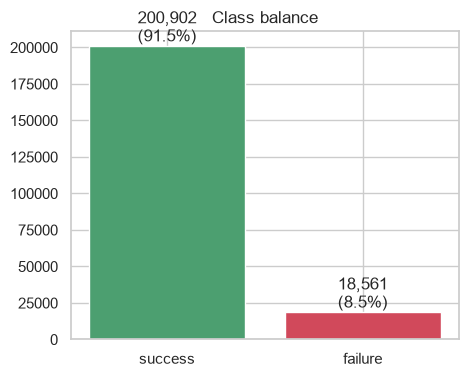

In [488]:
cb=data['label'].value_counts().sort_index()
plt.figure(figsize=(5,4))
plt.bar(["success","failure"],cb.values,color=["#4c9f70","#d1495b"])
for i,v in enumerate(cb.values): plt.text(i,v,f"{v:,}\n({v/len(data):.1%})",ha="center",va="bottom")
plt.title("Class balance")
plt.show()

**Missing values.** Workflow history is missing for runs without a `workflow_id`, and the first run of a repository has no history. The imputers and missing-value indicators in the Pipeline handle this.

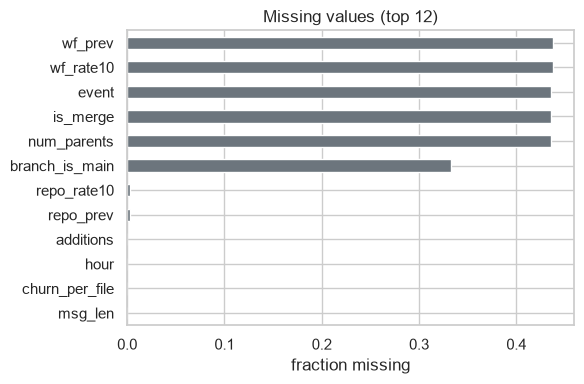

In [489]:
miss=data[FEATURES].isna().mean().sort_values(ascending=False).head(12)
plt.figure(figsize=(6,4))
miss.iloc[::-1].plot.barh(color="#6c757d")
plt.title("Missing values (top 12)")
plt.xlabel("fraction missing")
plt.tight_layout()
plt.show()

**Failure rate by trigger event.**

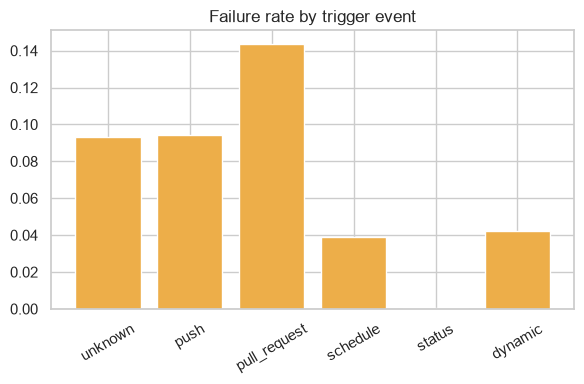

In [490]:
ev=data.groupby(data['event'].fillna("unknown"))['label'].agg(['mean','size']).sort_values('size',ascending=False).head(6)
plt.figure(figsize=(6,4))
plt.bar(ev.index,ev['mean'],color="#edae49")
plt.xticks(rotation=30)
plt.title("Failure rate by trigger event")
plt.tight_layout()
plt.show()

**Distribution of change size.** Churn is heavily skewed, which is why size features are log-transformed in the Pipeline.

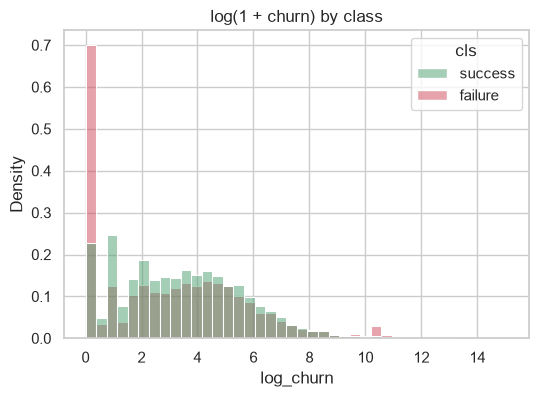

In [491]:
plt.figure(figsize=(6,4))
sns.histplot(data=data.assign(log_churn=np.log1p(data['churn_total'].clip(lower=0)),cls=data['label'].map({0:"success",1:"failure"})),x="log_churn",hue="cls",stat="density",common_norm=False,bins=40,palette={"success":"#4c9f70","failure":"#d1495b"})
plt.title("log(1 + churn) by class")
plt.show()

**Failure rate over time.**

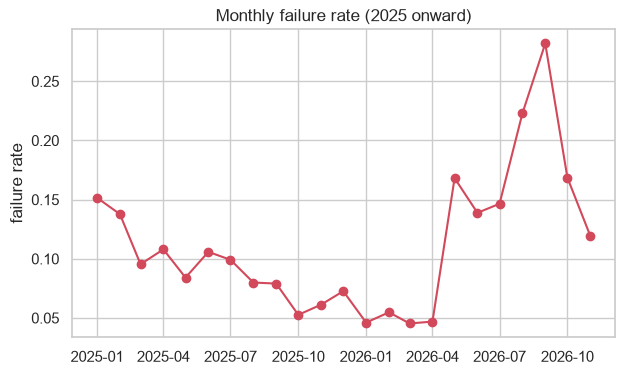

In [492]:
m=data[data['time']>="2025-01-01"].set_index('time')['label'].resample("MS").agg(['mean','size'])
plt.figure(figsize=(7,4))
plt.plot(m.index,m['mean'],marker="o",color="#d1495b")
plt.title("Monthly failure rate (2025 onward)")
plt.ylabel("failure rate")
plt.show()

**Correlations.**

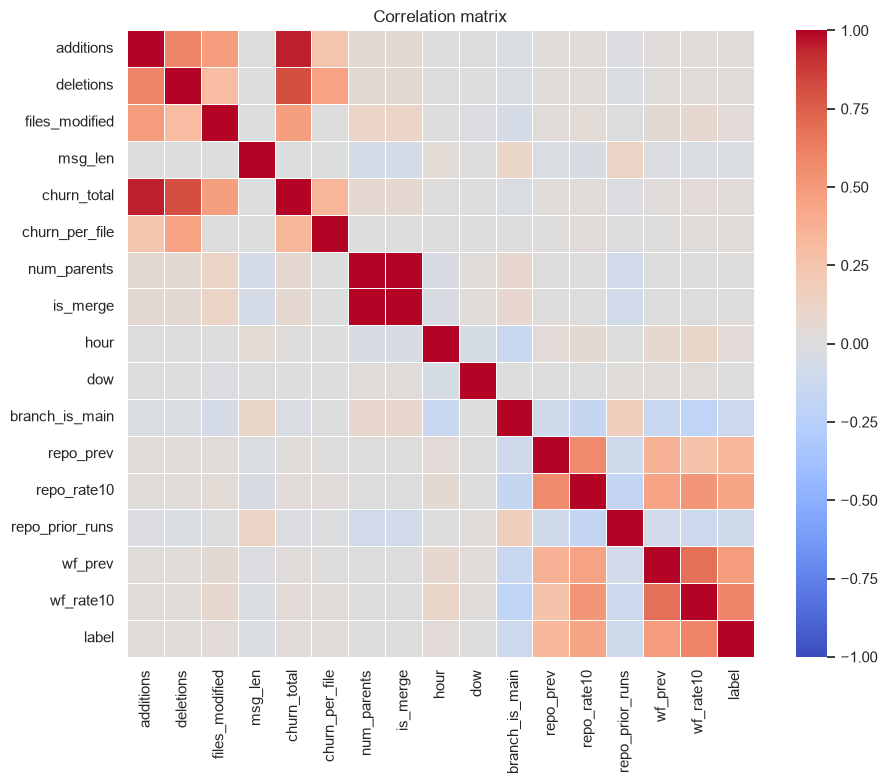

In [493]:
corr=data[LOG_COLS+NUM_COLS+['label']].corr()
plt.figure(figsize=(10,8))
sns.heatmap(corr,cmap="coolwarm",center=0,vmin=-1,vmax=1,square=True,linewidths=0.5)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

**Outliers.** A few very large commits exist, so size features are log-transformed rather than dropped.

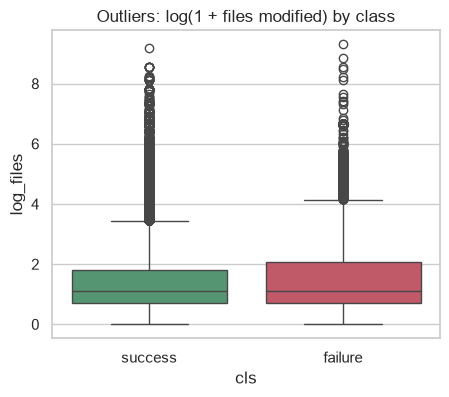

In [494]:
plt.figure(figsize=(5,4))
sns.boxplot(data=data.assign(log_files=np.log1p(data['files_modified'].clip(lower=0)),cls=data['label'].map({0:"success",1:"failure"})),x="cls",y="log_files",palette={"success":"#4c9f70","failure":"#d1495b"})
plt.title("Outliers: log(1 + files modified) by class")
plt.show()

**Failure rate by repository.** Some repositories fail far more often than others, which is why repository history is such a strong signal.

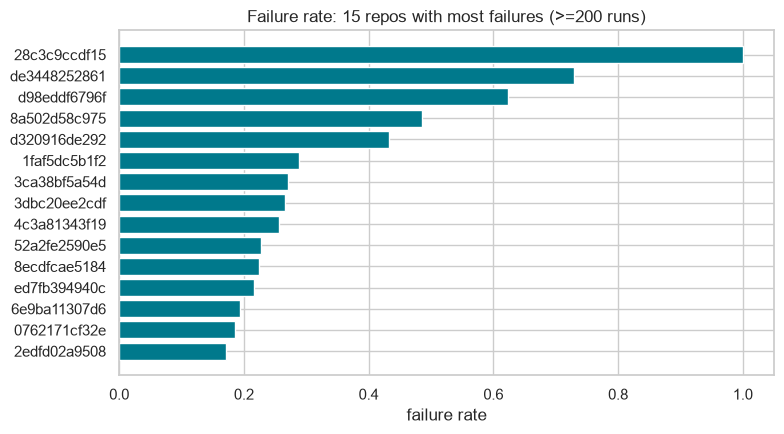

In [495]:
rr=data.groupby('repo_id')['label'].agg(['mean','size'])
rr=rr[rr['size']>=200].sort_values('mean',ascending=False).head(15)
plt.figure(figsize=(8,4.5))
plt.barh(rr.index[::-1],rr['mean'][::-1],color="#00798c")
plt.title("Failure rate: 15 repos with most failures (>=200 runs)")
plt.xlabel("failure rate")
plt.tight_layout()
plt.show()

## 6. Time-ordered split

Runs are sorted by time and split 70% train, 15% validation, 15% test, so the model is always evaluated on runs that happened after the ones it learned from.

In [496]:
n=len(data)
i1,i2=int(n*0.70),int(n*0.85)
train,val,test=data.iloc[:i1],data.iloc[i1:i2],data.iloc[i2:]

In [497]:
X_tr,y_tr=train[FEATURES],train['label']
X_va,y_va=val[FEATURES],val['label']
X_te,y_te=test[FEATURES],test['label']

In [498]:
for name,d in [("train",train),("val",val),("test",test)]:
    print(f"{name:5s} {len(d):7d} rows  {d['time'].min():%Y-%m-%d} -> {d['time'].max():%Y-%m-%d}  failure rate {d['label'].mean():.3f}")

train  153624 rows  2016-08-08 -> 2026-03-28  failure rate 0.082
val     32919 rows  2026-03-28 -> 2026-04-14  failure rate 0.049
test    32920 rows  2026-04-14 -> 2026-11-20  failure rate 0.130


## 7. Preprocessing Pipeline

All imputing, log transforming, scaling and encoding live inside a scikit-learn `Pipeline`, so they are fitted on the training data only.

- Size features: median imputation, `log(1 + x)`, scaling.
- Numeric and history features: median imputation with a missing-value indicator, scaling.
- Trigger event: constant imputation and one-hot encoding, with unseen categories ignored.

In [499]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder,FunctionTransformer

In [500]:
import sys
sys.path.append(BASE)
from ci_utils import log1p_clip
print(log1p_clip.__module__)

ci_utils


In [501]:
prep=ColumnTransformer([
    ("log",Pipeline([("imp",SimpleImputer(strategy="median")),("log",FunctionTransformer(log1p_clip)),("sc",StandardScaler())]),LOG_COLS),
    ("num",Pipeline([("imp",SimpleImputer(strategy="median",add_indicator=True)),("sc",StandardScaler())]),NUM_COLS),
    ("cat",Pipeline([("imp",SimpleImputer(strategy="constant",fill_value="unknown")),("oh",OneHotEncoder(handle_unknown="ignore"))]),CAT_COLS)])
print(prep)

ColumnTransformer(transformers=[('log',
                                 Pipeline(steps=[('imp',
                                                  SimpleImputer(strategy='median')),
                                                 ('log',
                                                  FunctionTransformer(func=<function log1p_clip at 0x000001E7BCF6D0C0>)),
                                                 ('sc', StandardScaler())]),
                                 ['additions', 'deletions', 'files_modified',
                                  'msg_len', 'churn_total', 'churn_per_file']),
                                ('num',
                                 Pipeline(steps=[('imp',
                                                  SimpleImputer(add_indicator=True,
                                                                strategy='median')),
                                                 ('sc', StandardScaler())]),
                                 ['num_parents', 'is_merge', 

In [502]:
Xt=clone(prep).fit(X_tr).transform(X_va)
print(Xt.shape)

(32919, 38)


## 8. Baselines

Two simple baselines set the bar the real models must beat: always predicting success, and repeating the previous run's outcome.

In [503]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score,precision_score,recall_score,roc_auc_score,average_precision_score
dummy=Pipeline([("prep",clone(prep)),("clf",DummyClassifier(strategy="most_frequent"))]).fit(X_tr,y_tr)
p_dummy_val=dummy.predict_proba(X_va)[:,1]
print(p_dummy_val[:5])

[0. 0. 0. 0. 0.]


In [504]:
rule_val=val['wf_prev'].fillna(val['repo_prev']).fillna(0).values
print(rule_val[:5])

[0. 0. 0. 0. 0.]


In [505]:
base_rows=[]
for name,proba in [("Baseline: majority class",p_dummy_val),("Baseline: previous-run outcome",rule_val)]:
    pred=(proba>=0.5).astype(int)
    base_rows.append({"Model":name,"macro_F1":f1_score(y_va,pred,average="macro"),"fail_F1":f1_score(y_va,pred,pos_label=1),"fail_prec":precision_score(y_va,pred,zero_division=0),"fail_rec":recall_score(y_va,pred),"ROC_AUC":roc_auc_score(y_va,proba),"PR_AUC":average_precision_score(y_va,proba)})
base_df=pd.DataFrame(base_rows).set_index("Model").round(3)
print(base_df)

                                macro_F1  fail_F1  fail_prec  fail_rec  \
Model                                                                    
Baseline: majority class           0.487    0.000      0.000     0.000   
Baseline: previous-run outcome     0.781    0.584      0.584     0.585   

                                ROC_AUC  PR_AUC  
Model                                            
Baseline: majority class          0.500   0.049  
Baseline: previous-run outcome    0.782   0.362  


## 9. Models and tuning

Six algorithms from the course are compared: Logistic Regression, Random Forest, Histogram Gradient Boosting, Decision Tree, KNN and Linear SVM.

Each is tuned with `RandomizedSearchCV` and 5-fold cross-validation. Because the data is time-ordered, the folds come from `TimeSeriesSplit(n_splits=5)`, where each fold trains on earlier runs and validates on later ones, rather than shuffled folds. To keep tuning fast, the search runs on the most recent training rows (time order kept), and the chosen settings are then refit on all of the training data. The scoring metric is macro-F1.

In [506]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier,HistGradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV,TimeSeriesSplit

In [507]:
TUNE_ROWS=20000 if QUICK else 80000
N_ITER=2 if QUICK else 8
N_TREES=60 if QUICK else 200
print(TUNE_ROWS,N_ITER,N_TREES)
print("Tuning uses the most recent",min(TUNE_ROWS,len(X_tr)),"of",len(X_tr),"training rows (time order kept). Final models are refit on all",len(X_tr),"training rows.")

80000 8 200
Tuning uses the most recent 80000 of 153624 training rows (time order kept). Final models are refit on all 153624 training rows.


In [508]:
cv=TimeSeriesSplit(n_splits=5)
X_sub,y_sub=X_tr.iloc[-TUNE_ROWS:],y_tr.iloc[-TUNE_ROWS:]
fitted={}
print(X_sub.shape)

(80000, 17)


In [509]:
lr_grid=RandomizedSearchCV(Pipeline([("prep",clone(prep)),("clf",LogisticRegression(max_iter=500,class_weight="balanced"))]),{"clf__C":[0.01,0.1,1,10]},n_iter=min(N_ITER,4),scoring="f1_macro",cv=cv,random_state=RANDOM_STATE,n_jobs=1,refit=False)
lr_grid.fit(X_sub,y_sub)
print("Logistic Regression:",lr_grid.best_params_,lr_grid.best_score_)

Logistic Regression: {'clf__C': 0.01} 0.6139327088473966


In [510]:
fitted["Logistic Regression"]=Pipeline([("prep",clone(prep)),("clf",LogisticRegression(max_iter=500,class_weight="balanced",C=lr_grid.best_params_["clf__C"]))]).fit(X_tr,y_tr)

In [511]:
rf_grid=RandomizedSearchCV(Pipeline([("prep",clone(prep)),("clf",RandomForestClassifier(n_estimators=N_TREES,class_weight="balanced_subsample",n_jobs=-1,random_state=RANDOM_STATE))]),{"clf__max_depth":[8,12,16,None],"clf__min_samples_leaf":[5,20,50]},n_iter=min(N_ITER,12),scoring="f1_macro",cv=cv,random_state=RANDOM_STATE,n_jobs=1,refit=False)
rf_grid.fit(X_sub,y_sub)
print("Random Forest:",rf_grid.best_params_,rf_grid.best_score_)

Random Forest: {'clf__min_samples_leaf': 5, 'clf__max_depth': None} 0.6654146699827259


In [512]:
fitted["Random Forest"]=Pipeline([("prep",clone(prep)),("clf",RandomForestClassifier(n_estimators=N_TREES,class_weight="balanced_subsample",n_jobs=-1,random_state=RANDOM_STATE))]).set_params(**rf_grid.best_params_).fit(X_tr,y_tr)

In [513]:
hgb_grid=RandomizedSearchCV(Pipeline([("prep",clone(prep)),("clf",HistGradientBoostingClassifier(class_weight="balanced",random_state=RANDOM_STATE))]),{"clf__learning_rate":[0.03,0.1,0.2],"clf__max_leaf_nodes":[15,31,63],"clf__min_samples_leaf":[20,50,100]},n_iter=min(N_ITER,27),scoring="f1_macro",cv=cv,random_state=RANDOM_STATE,n_jobs=1,refit=False)
hgb_grid.fit(X_sub,y_sub)
print("Hist Gradient Boosting:",hgb_grid.best_params_,hgb_grid.best_score_)

Hist Gradient Boosting: {'clf__min_samples_leaf': 50, 'clf__max_leaf_nodes': 63, 'clf__learning_rate': 0.1} 0.6018512970003966


In [514]:
fitted["Hist Gradient Boosting"]=Pipeline([("prep",clone(prep)),("clf",HistGradientBoostingClassifier(class_weight="balanced",random_state=RANDOM_STATE))]).set_params(**hgb_grid.best_params_).fit(X_tr,y_tr)
print(list(fitted))

['Logistic Regression', 'Random Forest', 'Hist Gradient Boosting']


### More algorithms: Decision Tree, KNN and Linear SVM

In [515]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

In [516]:
dt_grid=RandomizedSearchCV(Pipeline([("prep",clone(prep)),("clf",DecisionTreeClassifier(class_weight="balanced",random_state=RANDOM_STATE))]),{"clf__max_depth":[4,6,8,12],"clf__min_samples_leaf":[20,50,100]},n_iter=min(N_ITER,12),scoring="f1_macro",cv=cv,random_state=RANDOM_STATE,n_jobs=1,refit=False)
dt_grid.fit(X_sub,y_sub)
print("Decision Tree:",dt_grid.best_params_,dt_grid.best_score_)

Decision Tree: {'clf__min_samples_leaf': 100, 'clf__max_depth': 6} 0.5660326553033128


In [517]:
fitted["Decision Tree"]=Pipeline([("prep",clone(prep)),("clf",DecisionTreeClassifier(class_weight="balanced",random_state=RANDOM_STATE))]).set_params(**dt_grid.best_params_).fit(X_tr,y_tr)

In [518]:
knn_grid=RandomizedSearchCV(Pipeline([("prep",clone(prep)),("clf",KNeighborsClassifier(n_jobs=-1))]),{"clf__n_neighbors":[5,15,31,51],"clf__weights":["uniform","distance"]},n_iter=min(N_ITER,8),scoring="f1_macro",cv=cv,random_state=RANDOM_STATE,n_jobs=1,refit=False)
knn_grid.fit(X_sub,y_sub)
print("KNN:",knn_grid.best_params_,knn_grid.best_score_)

KNN: {'clf__weights': 'distance', 'clf__n_neighbors': 5} 0.6320690402331592


In [519]:
fitted["KNN"]=Pipeline([("prep",clone(prep)),("clf",KNeighborsClassifier(n_jobs=-1))]).set_params(**knn_grid.best_params_).fit(X_tr,y_tr)

In [520]:
svm_grid=RandomizedSearchCV(Pipeline([("prep",clone(prep)),("clf",CalibratedClassifierCV(LinearSVC(class_weight="balanced",dual="auto",max_iter=2000),cv=3))]),{"clf__estimator__C":[0.01,0.1,1]},n_iter=min(N_ITER,3),scoring="f1_macro",cv=cv,random_state=RANDOM_STATE,n_jobs=1,refit=False)
svm_grid.fit(X_sub,y_sub)
print("Linear SVM:",svm_grid.best_params_,svm_grid.best_score_)

Linear SVM: {'clf__estimator__C': 0.1} 0.6305898733040104


In [521]:
fitted["Linear SVM"]=Pipeline([("prep",clone(prep)),("clf",CalibratedClassifierCV(LinearSVC(class_weight="balanced",dual="auto",max_iter=2000),cv=3))]).set_params(**svm_grid.best_params_).fit(X_tr,y_tr)
print(list(fitted))

['Logistic Regression', 'Random Forest', 'Hist Gradient Boosting', 'Decision Tree', 'KNN', 'Linear SVM']


In [522]:
models_used=pd.DataFrame([
    ("Baseline 1","Majority class","Always predicts success"),
    ("Baseline 2","Previous-run outcome","Repeats the last run's result"),
    ("Model 1","Logistic Regression","Linear model, easy to explain"),
    ("Model 2","Decision Tree","Simple if/else rules"),
    ("Model 3","KNN","Looks at the most similar past runs"),
    ("Model 4","Linear SVM","Linear boundary, probabilities calibrated"),
    ("Model 5","Random Forest","Many trees voting (bagging)"),
    ("Model 6","Hist Gradient Boosting","Trees built one after another (boosting)")],
    columns=["Role","Algorithm","In one line"])
print(models_used.to_string(index=False))

      Role              Algorithm                               In one line
Baseline 1         Majority class                   Always predicts success
Baseline 2   Previous-run outcome             Repeats the last run's result
   Model 1    Logistic Regression             Linear model, easy to explain
   Model 2          Decision Tree                      Simple if/else rules
   Model 3                    KNN       Looks at the most similar past runs
   Model 4             Linear SVM Linear boundary, probabilities calibrated
   Model 5          Random Forest               Many trees voting (bagging)
   Model 6 Hist Gradient Boosting  Trees built one after another (boosting)


Class weights make the raw model outputs useful for ranking but not directly interpretable as failure probabilities. After selecting the model using validation macro-F1, a sigmoid (Platt) calibrator is fitted on the time-ordered validation split. The calibrated validation probabilities are used to select the decision threshold and risk bands. The final test set remains untouched until evaluation.


In [523]:
val_probs={name:pipe.predict_proba(X_va)[:,1] for name,pipe in fitted.items()}
thresholds={}
for name,p in val_probs.items():
    grid=np.linspace(0.05,0.95,91)
    scores=[f1_score(y_va,(p>=t).astype(int),average="macro") for t in grid]
    thresholds[name]=float(grid[int(np.argmax(scores))])
print(thresholds)

{'Logistic Regression': 0.8499999999999999, 'Random Forest': 0.62, 'Hist Gradient Boosting': 0.8599999999999999, 'Decision Tree': 0.8999999999999999, 'KNN': 0.5299999999999999, 'Linear SVM': 0.22999999999999998}


In [524]:
model_rows=[]
for name,p in val_probs.items():
    pred=(p>=thresholds[name]).astype(int)
    model_rows.append({"Model":name,"macro_F1":f1_score(y_va,pred,average="macro"),"fail_F1":f1_score(y_va,pred,pos_label=1),"fail_prec":precision_score(y_va,pred,zero_division=0),"fail_rec":recall_score(y_va,pred),"ROC_AUC":roc_auc_score(y_va,p),"PR_AUC":average_precision_score(y_va,p),"threshold":thresholds[name]})
model_df=pd.DataFrame(model_rows).set_index("Model").round(3)
print(model_df)

                        macro_F1  fail_F1  fail_prec  fail_rec  ROC_AUC  \
Model                                                                     
Logistic Regression        0.805    0.628      0.695     0.573    0.929   
Random Forest              0.805    0.628      0.708     0.564    0.938   
Hist Gradient Boosting     0.807    0.631      0.745     0.547    0.941   
Decision Tree              0.801    0.620      0.748     0.529    0.925   
KNN                        0.789    0.595      0.748     0.494    0.847   
Linear SVM                 0.801    0.620      0.672     0.576    0.924   

                        PR_AUC  threshold  
Model                                      
Logistic Regression      0.652       0.85  
Random Forest            0.676       0.62  
Hist Gradient Boosting   0.693       0.86  
Decision Tree            0.675       0.90  
KNN                      0.572       0.53  
Linear SVM               0.635       0.23  


In [525]:
val_table=pd.concat([base_df,model_df])
print(val_table)

                                macro_F1  fail_F1  fail_prec  fail_rec  \
Model                                                                    
Baseline: majority class           0.487    0.000      0.000     0.000   
Baseline: previous-run outcome     0.781    0.584      0.584     0.585   
Logistic Regression                0.805    0.628      0.695     0.573   
Random Forest                      0.805    0.628      0.708     0.564   
Hist Gradient Boosting             0.807    0.631      0.745     0.547   
Decision Tree                      0.801    0.620      0.748     0.529   
KNN                                0.789    0.595      0.748     0.494   
Linear SVM                         0.801    0.620      0.672     0.576   

                                ROC_AUC  PR_AUC  threshold  
Model                                                       
Baseline: majority class          0.500   0.049        NaN  
Baseline: previous-run outcome    0.782   0.362        NaN  
Logistic Regres

In [526]:
best_name=model_df['macro_F1'].idxmax()
final=fitted[best_name]

# Platt scaling: calibrate the selected class-weighted model on the later,
# time-ordered validation split. The test split is not used for calibration.
from sklearn.linear_model import LogisticRegression

def calibration_input(probabilities):
    probabilities=np.clip(np.asarray(probabilities, dtype=float), 1e-6, 1-1e-6)
    logits=np.log(probabilities/(1-probabilities))
    return logits.reshape(-1, 1)

raw_p_va=final.predict_proba(X_va)[:,1]
probability_calibrator=LogisticRegression(solver="lbfgs", max_iter=1000)
probability_calibrator.fit(calibration_input(raw_p_va), y_va)
p_va_cal=probability_calibrator.predict_proba(calibration_input(raw_p_va))[:,1]

# Re-select the operating threshold on calibrated validation probabilities.
calibration_threshold_grid=np.linspace(0.05,0.95,91)
calibration_threshold_scores=[
    f1_score(y_va,(p_va_cal>=t).astype(int),average="macro")
    for t in calibration_threshold_grid
]
thr=float(calibration_threshold_grid[int(np.argmax(calibration_threshold_scores))])
print("Selected model:",best_name,"| calibrated threshold",thr)


Selected model: Hist Gradient Boosting | threshold 0.8599999999999999


## 11. Final evaluation on the held-out test set

The selected model and its threshold are now scored on the test set. The baselines are scored the same way for comparison.

In [527]:
p_te_raw=final.predict_proba(X_te)[:,1]
p_te=probability_calibrator.predict_proba(calibration_input(p_te_raw))[:,1]
print(p_te.shape)


(32920,)


In [528]:
p_dummy_te=Pipeline([("prep",clone(prep)),("clf",DummyClassifier(strategy="most_frequent"))]).fit(X_tr,y_tr).predict_proba(X_te)[:,1]
rule_te=test['wf_prev'].fillna(test['repo_prev']).fillna(0).values

In [529]:
test_rows=[]
for name,proba,t in [("Baseline: majority class",p_dummy_te,0.5),("Baseline: previous-run outcome",rule_te,0.5),(f"{best_name} (tuned)",p_te,thr)]:
    pred=(proba>=t).astype(int)
    test_rows.append({"Model":name,"macro_F1":f1_score(y_te,pred,average="macro"),"fail_F1":f1_score(y_te,pred,pos_label=1),"fail_prec":precision_score(y_te,pred,zero_division=0),"fail_rec":recall_score(y_te,pred),"ROC_AUC":roc_auc_score(y_te,proba),"PR_AUC":average_precision_score(y_te,proba)})
test_table=pd.DataFrame(test_rows).set_index("Model").round(3)
print(test_table)

                                macro_F1  fail_F1  fail_prec  fail_rec  \
Model                                                                    
Baseline: majority class           0.465    0.000      0.000     0.000   
Baseline: previous-run outcome     0.697    0.473      0.474     0.472   
Hist Gradient Boosting (tuned)     0.689    0.447      0.545     0.379   

                                ROC_AUC  PR_AUC  
Model                                            
Baseline: majority class          0.500   0.130  
Baseline: previous-run outcome    0.697   0.292  
Hist Gradient Boosting (tuned)    0.845   0.504  


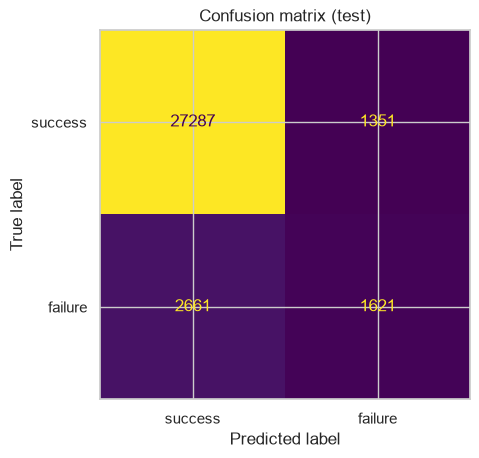

In [530]:
from sklearn.metrics import ConfusionMatrixDisplay,RocCurveDisplay,PrecisionRecallDisplay
ConfusionMatrixDisplay.from_predictions(y_te,(p_te>=thr).astype(int),display_labels=["success","failure"],colorbar=False)
plt.title("Confusion matrix (test)")
plt.show()

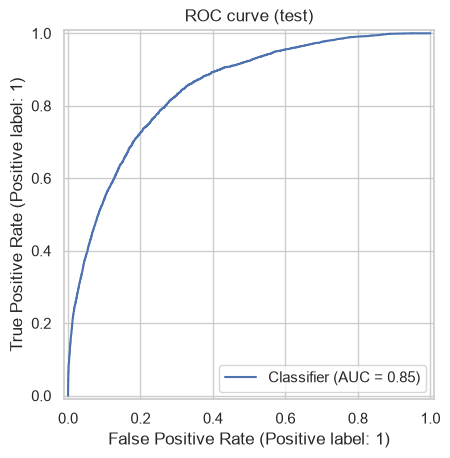

In [531]:
RocCurveDisplay.from_predictions(y_te,p_te)
plt.title("ROC curve (test)")
plt.show()

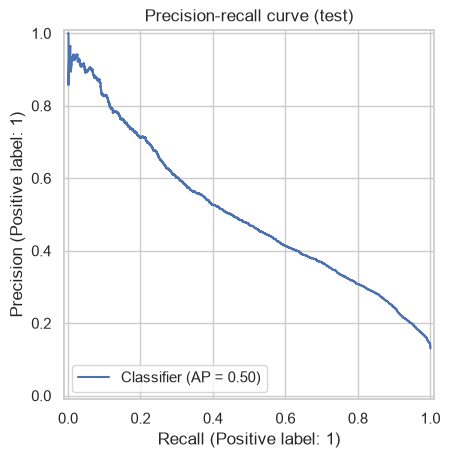

In [532]:
PrecisionRecallDisplay.from_predictions(y_te,p_te)
plt.title("Precision-recall curve (test)")
plt.show()

## 12. Over-fitting and under-fitting

Comparing the selected model's scores on train, validation and test shows whether it memorises the training data (large drop) or is too simple (low scores everywhere).

In [533]:
fit_rows=[]
for name,X,y in [("train",X_tr,y_tr),("validation",X_va,y_va),("test",X_te,y_te)]:
    raw_p=final.predict_proba(X)[:,1]
    p=probability_calibrator.predict_proba(calibration_input(raw_p))[:,1]
    pred=(p>=thr).astype(int)
    fit_rows.append({"split":name,"macro_F1":f1_score(y,pred,average="macro"),"fail_F1":f1_score(y,pred,pos_label=1),"ROC_AUC":roc_auc_score(y,p),"PR_AUC":average_precision_score(y,p)})
fit_check=pd.DataFrame(fit_rows).set_index("split").round(3)
print(fit_check)


            macro_F1  fail_F1  ROC_AUC  PR_AUC
split                                         
train          0.762    0.556    0.912   0.626
validation     0.807    0.631    0.941   0.693
test           0.689    0.447    0.845   0.504


In [534]:
gap=fit_check.loc["train","macro_F1"]-fit_check.loc["test","macro_F1"]
if gap>0.10:
    verdict="a large train-to-test gap, which points to over-fitting"
elif fit_check.loc["test","macro_F1"]<0.60:
    verdict="low scores on every split, which points to under-fitting"
else:
    verdict="a small gap between train and test, so no strong sign of over-fitting"
print(f"Train macro-F1 minus test macro-F1 is {gap:.3f}: {verdict}.")

Train macro-F1 minus test macro-F1 is 0.073: a small gap between train and test, so no strong sign of over-fitting.


## 13. Error analysis

Where does the selected model make its mistakes? False alarms are successful runs flagged as likely to fail. Missed failures are failing runs the model called safe.

In [535]:
from sklearn.metrics import confusion_matrix
pred_te=(p_te>=thr).astype(int)
tn,fp,fn,tp=confusion_matrix(y_te,pred_te).ravel()
print(f"true negatives {tn:,} | false alarms {fp:,} | missed failures {fn:,} | caught failures {tp:,}")

true negatives 27,287 | false alarms 1,351 | missed failures 2,661 | caught failures 1,621


In [536]:
err=test[["repo_id","event","label"]].copy()
err["event"]=err["event"].fillna("unknown")
err["pred"]=pred_te
err["false_alarm"]=((err["pred"]==1)&(err["label"]==0)).astype(int)
err["missed"]=((err["pred"]==0)&(err["label"]==1)).astype(int)
by_event=err.groupby("event").agg(runs=("label","size"),failure_rate=("label","mean"),false_alarms=("false_alarm","sum"),missed_failures=("missed","sum")).sort_values("runs",ascending=False).head(6)
print(by_event.round(3))

                runs  failure_rate  false_alarms  missed_failures
event                                                            
pull_request   17592         0.195           975             2091
push           10213         0.076           354              522
workflow_run    1396         0.021             9               24
status          1070         0.000             0                0
dynamic          893         0.020             8                6
issue_comment    690         0.001             0                1


In [537]:
by_repo=err.groupby("repo_id").agg(runs=("label","size"),failure_rate=("label","mean"),false_alarms=("false_alarm","sum"),missed_failures=("missed","sum"))
by_repo["errors"]=by_repo["false_alarms"]+by_repo["missed_failures"]
print(by_repo.sort_values("errors",ascending=False).head(5).round(3))

              runs  failure_rate  false_alarms  missed_failures  errors
repo_id                                                                
992014cf2f07  1905         0.201           176              306     482
1faf5dc5b1f2  1800         0.288           193              242     435
2edfd02a9508  1797         0.172           118              276     394
4c3a81343f19  1717         0.256           130              204     334
52a2fe2590e5  1800         0.227           132              178     310


## 14. What the model relies on

Permutation importance on a validation sample: how much macro-F1 drops when one feature is shuffled.

In [538]:
from sklearn.inspection import permutation_importance
sample=val.sample(min(8000,len(val)),random_state=RANDOM_STATE)
imp=permutation_importance(final,sample[FEATURES],sample['label'],scoring="f1_macro",n_repeats=3,random_state=RANDOM_STATE,n_jobs=1)
imp_s=pd.Series(imp.importances_mean,index=FEATURES).sort_values()
print(imp_s.tail(12))

churn_total       -0.001064
branch_is_main    -0.000937
deletions         -0.000754
is_merge           0.000000
repo_prev          0.000230
num_parents        0.000320
dow                0.000373
churn_per_file     0.000717
files_modified     0.001032
repo_prior_runs    0.001604
additions          0.003891
wf_rate10          0.220499
dtype: float64


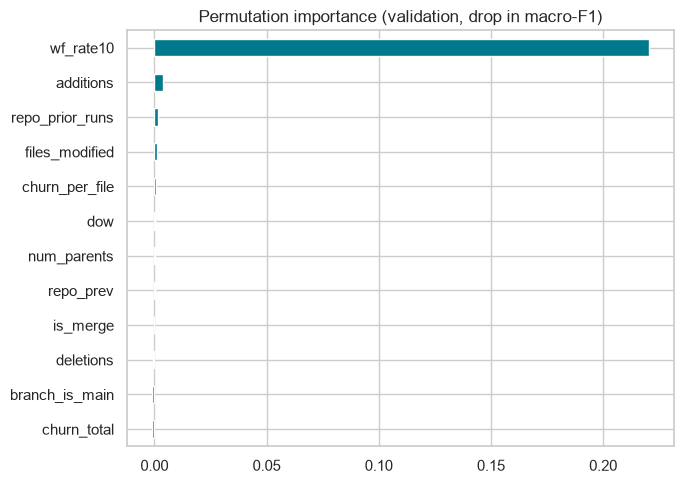

In [539]:
plt.figure(figsize=(7,5))
imp_s.tail(12).plot.barh(color="#00798c")
plt.title("Permutation importance (validation, drop in macro-F1)")
plt.tight_layout()
plt.show()

## 15. Risk levels

A run is **High** risk at or above the decision threshold. **Medium** starts at a lower cut-off, set so that 90% of the failures in the validation set score at or above it. Everything below is **Low**. The table checks that the observed failure rate rises from Low to High on both splits.

In [540]:
p_va_final=p_va_cal
low_cut=min(float(np.quantile(p_va_final[y_va.values==1],0.10)),thr)
risk_bands={"low_cut":low_cut,"high_cut":thr}
print(risk_bands)


{'low_cut': 0.1788567967392441, 'high_cut': 0.8599999999999999}


In [541]:
def band(p):
    return np.where(p>=risk_bands["high_cut"],"High",np.where(p>=risk_bands["low_cut"],"Medium","Low"))
rows=[]
for split,p,y in [("validation",p_va_final,y_va),("test",p_te,y_te)]:
    b=band(p)
    for lvl in ["Low","Medium","High"]:
        mask=b==lvl
        rows.append({"split":split,"risk level":lvl,"runs":int(mask.sum()),"share of runs":round(mask.mean(),3),"actual failure rate":round(float(y.values[mask].mean()),3) if mask.any() else np.nan})
risk_table=pd.DataFrame(rows)
print(risk_table.to_string(index=False))

     split risk level  runs  share of runs  actual failure rate
validation        Low 26312          0.799                0.006
validation     Medium  5411          0.164                0.106
validation       High  1196          0.036                0.745
      test        Low 13977          0.425                0.021
      test     Medium 15971          0.485                0.149
      test       High  2972          0.090                0.545


## 16. Save the final pipeline

The fitted Pipeline is saved with joblib together with its threshold, risk bands and the test-set failure rate of each risk level, which the app displays. `requirements.txt` is rewritten from the packages used here, so the pinned versions match the ones that created the model.

In [542]:
import joblib
te_band=band(p_te)
risk_rates={lvl:(float(y_te.values[te_band==lvl].mean()) if (te_band==lvl).any() else 0.0) for lvl in ["Low","Medium","High"]}
risk_rates["overall"]=float(y_te.mean())
print(risk_rates)
bundle={"pipeline":final,"probability_calibrator":probability_calibrator,"calibration_method":"Platt scaling on time-ordered validation split","threshold":thr,"features":FEATURES,"log_cols":LOG_COLS,"num_cols":NUM_COLS,"cat_cols":CAT_COLS,"model_name":best_name,"risk_bands":risk_bands,"risk_rates":risk_rates,"test_metrics":test_table.loc[f"{best_name} (tuned)"].to_dict(),"feature_medians":X_tr[LOG_COLS+NUM_COLS].median().to_dict()}
joblib.dump(bundle,f"{MODEL_DIR}/ci_failure_model.joblib")
print("saved",f"{MODEL_DIR}/ci_failure_model.joblib")


{'Low': 0.0206052801030264, 'Medium': 0.14858180452069375, 'High': 0.5454239569313594, 'overall': 0.13007290400972055}
saved ../models/ci_failure_model.joblib


In [543]:
from importlib.metadata import version
with open(f"{BASE}/requirements.txt","w") as f:
    for pkg in ["numpy","pandas","scikit-learn","matplotlib","seaborn","joblib","streamlit","flask","gradio"]:
        try: f.write(f"{pkg}=={version(pkg)}\n")
        except Exception: pass
print(open(f"{BASE}/requirements.txt").read())

numpy==2.5.4
pandas==3.0.6
scikit-learn==1.9.1
matplotlib==3.11.2
seaborn==0.13.2
joblib==1.6.0
streamlit==1.67.0
flask==3.1.3



In [544]:
data.drop(columns=['wf_key']).to_csv(f"{DATA_DIR}/cleaned_runs.csv.gz",index=False)
print("saved cleaned data")

saved cleaned data


## 17. Limitations

- The displayed failure probability is sigmoid-calibrated on the time-ordered validation split. Calibration is not a guarantee and may weaken as repositories and workflows change.
- Failures are rare, so some alerts are false alarms.
- Most of the signal comes from run history, so a brand new repository or workflow has less history available and is predicted mainly from change size and trigger.
- Repositories change over time, so the model should be retrained and recalibrated periodically.
